# 25장 · RAG 입력 계약과 오류 진단

입력 계약은 함수가 받기로 한 필드와 자료형에 대한 약속입니다. 질문, 검색 결과, 프롬프트를 차례로 대조하면 RAG 오류의 시작점을 좁힐 수 있습니다.

휴관 요일을 물었는데 검색 결과로 대출 기간 문서가 나왔습니다. 질문, 검색 결과, 프롬프트에 들어간 본문, 답변의 출처를 순서대로 확인해 실패가 시작된 위치를 찾습니다.

실행을 확인한 커널은 Python 3.12.15입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요. 과제 셀에 직접 코드를 작성한 뒤 바로 아래에서 풀이를 펼쳐 보세요.


## 질문·문서·출처 필드 검증

입력까지 바꾸고 검색 코드를 고치면 무엇 때문에 결과가 달라졌는지 알 수 없습니다. 공통 개발 문항 dev-02와 그 기대 원문을 고정한 뒤 한 가지 조건씩 확인합니다.


### 셀 01 · 기대 근거와 검색 결과 비교

일부러 1쪽만 가져온 검색 결과를 준비했습니다. 개발 문항의 기대 ID와 비교합니다.

지금 살펴볼 실패는 검색이 비어 있는 경우와 다릅니다. 휴관을 물었는데 대출 문서가 돌아왔습니다. 먼저 실제 ID와 기대 ID를 비교한 뒤 답변 단계로 가세요.


In [1]:
documents = [
  {"id":"library-1","text":"도서 대출 기간은 14일입니다.","source":"가상 도서관 이용 안내","page":1},
  {"id":"library-2","text":"도서관은 월요일에 휴관합니다.","source":"가상 도서관 이용 안내","page":2},
  {"id":"library-3","text":"무인 반납함은 24시간 이용할 수 있습니다.","source":"가상 도서관 이용 안내","page":3}
]
case = {"question_id": "dev-02", "question": "휴관 요일은 언제인가요?", "expected_document_ids": ["library-2"]}
retrieved = [documents[0]]
ids = [doc["id"] for doc in retrieved]
print(case["expected_document_ids"][0] in ids)

False


False입니다. 대출 기간 문서만 가져왔으므로 생성 프롬프트를 고치기 전에 검색 범위와 전달한 질문부터 확인합니다.


### 셀 02 · 문서 ID로 검색 오류 진단

검색 뒤 단계만 볼 수 있도록 기대 원문을 포함한 자료를 한 건 넣습니다.


In [2]:
hits = [documents[1]]
print(hits[0]["text"])

도서관은 월요일에 휴관합니다.


월요일에 휴관한다는 문장이 있습니다. 이 자료로도 생성 입력에서 문장이 사라지면 원인은 검색보다 뒤에 있습니다.


## prepare_inputs()로 질문과 문맥 조립

이 장의 준비 함수는 질문과 자료를 validate 함수로 검사한 뒤 question, context 두 칸을 만들어야 합니다. 빈 목록은 정상적인 ‘근거 없음’으로 None을 반환합니다. 출처가 망가진 자료까지 None으로 처리하지 않습니다.

<!-- lesson-visual detail-repair -->
**빈 문서 목록과 잘못된 쪽 번호는 어디로 갈까요?**

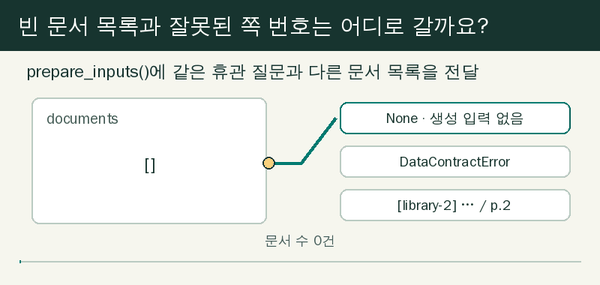

같은 질문에 문서 목록만 바꿔 prepare_inputs() 풀이의 세 경로를 비교합니다. 빈 목록은 None을 돌려주고, 쪽 번호 0은 검사 중 예외를 일으킵니다. 2쪽인 정상 문서만 출처가 붙은 문맥으로 조립됩니다.
<!-- /lesson-visual detail-repair -->


### 셀 03 · 메타데이터의 쪽 번호 검증

23장의 자료 계약을 검사하는 함수들을 그대로 사용합니다. 페이지 번호만 0으로 바뀌었습니다.


In [3]:
import re

class DataContractError(ValueError):
    """저장된 근거 또는 검색 결과의 형태가 잘못되었습니다."""

def validate_request(question, k=2):
    if not isinstance(question, str) or not question.strip():
        raise ValueError("질문은 비어 있지 않은 문자열이어야 합니다.")
    if isinstance(k, bool) or not isinstance(k, int) or k < 1:
        raise ValueError("k는 양의 정수여야 합니다.")
    return question.strip()

def validate_documents(documents):
    if not isinstance(documents, list):
        raise DataContractError("검색 결과는 문서 목록이어야 합니다.")
    rows, seen = [], set()
    for item in documents:
        if not isinstance(item, dict):
            raise DataContractError("출처 객체가 필요합니다. 문자열 상태는 먼저 변환하세요.")
        if any(not isinstance(item.get(key), str) or not item[key].strip()
               for key in ("id", "text", "source")):
            raise DataContractError("id·본문·출처가 필요합니다.")
        page = item.get("page")
        if isinstance(page, bool) or not isinstance(page, int) or page < 1:
            raise DataContractError("페이지는 1 이상의 정수여야 합니다.")
        if item["id"] in seen:
            raise DataContractError("문서 ID가 중복되었습니다.")
        # 인용 문법 [id]와 충돌하는 ID는 입력 단계에서 막습니다.
        if not re.fullmatch(r"[A-Za-z0-9_.:-]+", item["id"]):
            raise DataContractError("문서 ID는 영문·숫자·_ . : -만 사용합니다.")
        seen.add(item["id"])
        rows.append({key: item[key] for key in ("id", "text", "source", "page")})
    return rows

def format_context(documents):
    return "\n\n".join(f"[{d['id']}] {d['source']} / p.{d['page']}\n{d['text']}"
                       for d in validate_documents(documents))

bad_page = {**hits[0], "page": 0}
try:
    validate_documents([bad_page])
except ValueError as error:
    print(error)

페이지는 1 이상의 정수여야 합니다.


‘페이지는 1 이상의 정수여야 합니다.’라는 문구가 나옵니다. 잘못된 원자료가 빈 검색 결과로 숨지 않았습니다.


### 과제 04 · prepare_inputs()의 입력 계약

질문 바깥 공백을 정리하고 문서 목록을 검사하세요. 유효한 빈 목록은 None으로, 근거가 있으면 question과 context가 있는 사전으로 돌려줍니다.


In [4]:
def prepare_inputs(question, documents):
    pass  # 제공된 검사·문맥 함수를 사용하세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>def prepare_inputs(question, documents):
    question = validate_request(question)
    checked = validate_documents(documents)
    if not checked:
        return None
    return {&quot;question&quot;: question, &quot;context&quot;: format_context(checked)}

prepared = prepare_inputs(&quot;  휴관 요일은 언제인가요?  &quot;, hits)
print(prepared[&quot;context&quot;])</code></pre>
<p>실행 결과</p><pre><code>[library-2] 가상 도서관 이용 안내 / p.2
도서관은 월요일에 휴관합니다.</code></pre>
<p>첫 줄에 [library-2], 자료 이름, p.2가 남고 다음 줄에 원문이 옵니다. 입력 검사는 빈 목록 처리보다 먼저 하므로 질문까지 비어 있을 때는 오류를 놓치지 않습니다.</p>
</details>


## 고정 입력을 사용한 회귀 검사

동료가 다시 확인하려면 질문과 원문 ID를 기록한 뒤 어떤 단계에서 비교했는지 밝혀야 합니다. 생성 모델을 전혀 부르지 않고도 문맥까지 재현한 사실을 보고할 수 있습니다.


### 과제 05 · 고정 입력의 회귀 결과 기록

hits에 실제로 들었던 ID와 쪽을 읽어 교정 전 자료의 ID와 함께 출력하세요.


In [5]:
# retrieved와 hits에서 ID와 쪽 번호를 읽으세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>print(&quot;처음 검색한 ID:&quot;, retrieved[0][&quot;id&quot;])
print(&quot;기대 원문과 대조한 ID:&quot;, hits[0][&quot;id&quot;], &quot;/ 쪽:&quot;, hits[0][&quot;page&quot;])</code></pre>
<p>실행 결과</p><pre><code>처음 검색한 ID: library-1
기대 원문과 대조한 ID: library-2 / 쪽: 2</code></pre>
<p>처음의 library-1과 확인용 library-2, 2쪽을 구별했습니다. 이 셀은 올바른 자료를 직접 넣은 경로만 확인합니다. 실제 저장소 설정을 고쳐 검색이 복구됐다는 주장에는 같은 질문으로 저장소를 다시 조회한 결과가 필요합니다.</p>
</details>


## 돌아보기

질문이 비었을 때, 출처가 없을 때, 검색 결과가 비었을 때 중 하나를 골라 진단해 보세요. 다음 장에서 상태에 결과를 담더라도 오류와 빈 목록을 구분하는 원칙은 그대로입니다.
